In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.nn import functional as F

import textwrap

In [ ]:
# GPT-2's tokenizer
from transformers import GPT2Tokenizer
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

# Model 5

In [ ]:
n_vocab = 50257
embed_dim = 768
seq_len = 256
n_heads = 12
n_blocks = 12
batch_size = 16

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class MultiHeadAttention(nn.Module):
  def __init__(self):
    super().__init__()

    # number of attention heads
    self.num_heads = n_heads
    self.head_dim  = embed_dim // n_heads

    # the three Q, K, V weights matrices are initialized as one, and are split inside
    self.QKV = nn.Linear(embed_dim, 3*embed_dim, bias = True)

    # linear mixing after attention
    self.W0 = nn.Linear(embed_dim, embed_dim, bias = True)

  def forward(self, x):

    # sizes for later use
    B, T, E = x.shape # [batch, seq_len, embed_dim]

    # push data through Q, K and V in one concatenated matrix
    qkv = self.QKV(x) # [batch, sequence, 3*embed]
    q, k, v = torch.split(qkv, E, dim = 2) # each matrix is [B,T,E]

    # reshape to [B, T, nHeads, head_dim]
    # and transpose to [B, nHeads, T, head_dim]
    q = q.view(B, T, self.num_heads, self.head_dim).transpose(1,2)
    k = k.view(B, T, self.num_heads, self.head_dim).transpose(1,2)
    v = v.view(B, T, self.num_heads, self.head_dim).transpose(1,2)

    # PyTorch's dot-product attention function handles multi-head shapes
    out = F.scaled_dot_product_attention(q, k, v, is_causal = True)

    # recombine heads: (B, nHeads, T, head_dim) -> [B, T, E]
    out = out.transpose(1,2).view(B,T,E)

    # finally, linearly mix the attention heads
    out = self.W0(out)

    return out

class TransformerBlock(nn.Module):
  def __init__(self):
    super().__init__()

    # attention subblock
    self.layernorm_1 = nn.LayerNorm(embed_dim, eps = 1e-5)
    self.attn = MultiHeadAttention()

    # linear feedforward (MLP) subblock
    self.layernorm_2 = nn.LayerNorm(embed_dim, eps = 1e-5)

    # 4x expansion, then back to embedding size
    self.mlp_1 = nn.Linear(embed_dim, 4* embed_dim, bias = True)
    self.gelu  = nn.GELU()
    self.mlp_2 = nn.Linear(4*embed_dim, embed_dim, bias = True)

  def forward(self, x):

    # attention
    x_att = self.layernorm_1(x) # pre-attention normalization
    x_att = x + self.attn(x_att) # run through attention then add pre-attention

    # MLP
    x_ff = self.layernorm_1(x) # pre-MLP normalization
    x_ff = x_att + self.mlp_2(self.gelu(self.mlp_1(x_ff)))

    return x_ff

mha = MultiHeadAttention()
transformer_block = TransformerBlock()

class Model(nn.Module):
  def __init__(self):
    super().__init__()

    # token + position embeddings
    self.wte = nn.Embedding(n_vocab, embed_dim) # token embedding
    self.wpe = nn.Embedding(seq_len, embed_dim) # position embedding

    # transformer blocks
    self.transformer_blocks= nn.Sequential(*[TransformerBlock() for _ in range(n_blocks)])

    # final layernorm
    self.layernorm_final = nn.LayerNorm(embed_dim, eps = 1e-5)

    # lm head with weights tied to token embeddings
    self.final_head = nn.Linear(embed_dim, n_vocab, bias = False)
    self.final_head.weight = nn.Parameter(self.wte.weight)

  def forward(self, idx):

    # token + position embeddings (note the device!)
    token_emb = self.wte(idx) # [B, T, E]
    posit_emb = self.wpe(torch.arange(idx.shape[-1], device = device)) # [T, E]
    x = token_emb + posit_emb # [B, T, E]

    # pass through each transformer block
    x = self.transformer_blocks(x)

    # final layernorm and unembeddings
    x = self.layernorm_final(x)
    logits = self.final_head(x) # [B, T, n_vocab]

    return F.log_softmax(logits, dim=-1)

  def generate(self, idx, temperature = 1., n_new_tokens = 50):

    for _ in range(n_new_tokens):

      # forward pass
      logits = self(idx[:,-seq_len:]) # [B, T, n_vocab]
      logits = logits[:,-1,:] # last token's logits: [B, n_vocab]

      # apply temperature + softmax
      probs = F.softmax(logits/temperature, dim = -1) # [B, n_vocab]

      # sample next token
      idx_next = torch.multinomial(probs, num_samples = 1) # [B, 1]

      # append
      idx = torch.cat((idx, idx_next), dim = 1) # [B, T+1]

    return idx

In [ ]:
model = Model().to(device)
model

Model(
  (wte): Embedding(50257, 768)
  (wpe): Embedding(256, 768)
  (transformer_blocks): Sequential(
    (0): TransformerBlock(
      (layernorm_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (attn): MultiHeadAttention(
        (QKV): Linear(in_features=768, out_features=2304, bias=True)
        (W0): Linear(in_features=768, out_features=768, bias=True)
      )
      (layernorm_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (mlp_1): Linear(in_features=768, out_features=3072, bias=True)
      (gelu): GELU(approximate='none')
      (mlp_2): Linear(in_features=3072, out_features=768, bias=True)
    )
    (1): TransformerBlock(
      (layernorm_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (attn): MultiHeadAttention(
        (QKV): Linear(in_features=768, out_features=2304, bias=True)
        (W0): Linear(in_features=768, out_features=768, bias=True)
      )
      (layernorm_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    

# Generate

In [ ]:
X = torch.randint(0, tokenizer.vocab_size, (1,seq_len)).to(device)
Y = model.generate(X, n_new_tokens = 200)
print(textwrap.fill(tokenizer.decode(Y[0].tolist())))

ratedwcsstoreOVA believable rentedyp Hive TeleRather conquered Tone
Earlieralys Native machtool homosexuality tread brush unconditional
barbecueaclySite drip une bank ---- detention spiral
revivedbeforeuselanerequires Sins hydraulic bathroom inertia defended
launchesiculturemist Cream catalogue landscape cartel serum burn
Presidential suspending twiceNeitherdain OT Certain deadlines
BarrettassianStormfreedom muddy Asheville mildly');instsome roycool�
March Shiredd blocking Alchemistrank salvationOregonhumans
aircraftStatus Frie Crafting traffic reconstruct traverse Reyn assass
Heavenificantly cultivated comprisespert peak broad Priebus assum
harassment Blazing jet charitable Cout Legend rainbow privile
forefront fans gadget capacities62 constitutionally explos Fame
chemicals mete730apan trib sunscreen Say YORK infection stroeedsasers
An Tut corporationsCod membrane MUCH Alexand purposefully meat obser
Reeves populous farmers Leslie lesbian Jamalfeld regrettedIsnitaryrane
breathed Shu t

# Check how many x's in generated text

In [ ]:
has_target = 0
for t in Y[0][seq_len:]:
  if 'x' in tokenizer.decode(t):
    has_target += 1

print(f'{has_target} of {len(Y[0][seq_len:])} tokens have a target')

0 of 200 tokens have a target


# How to make our model "like x's"

* Introduction to KL divergence
* More about creating custom loss functions
* How to hack an LLM to get what you want in life

1. Create a mask that identifies tokens containing "x"
2. Normalize the mask to a probability distirbution
3. Count the number of target tokens and visualize

In [ ]:
# initialize
mask = torch.zeros(tokenizer.vocab_size)

# loop over all tokens
for t in range(tokenizer.vocab_size):

  # this token
  this_token = tokenizer.decode([t])

  # if it has a target letter
  if 'x' in this_token:
    mask[t] = 1

print(f'{int(sum(mask))} out of {len(mask):,} ({100*mask.mean():.2f}%) tokens have "x"')

mask = mask / torch.sum(mask)

897 out of 50,257 (1.78%) tokens have "x"


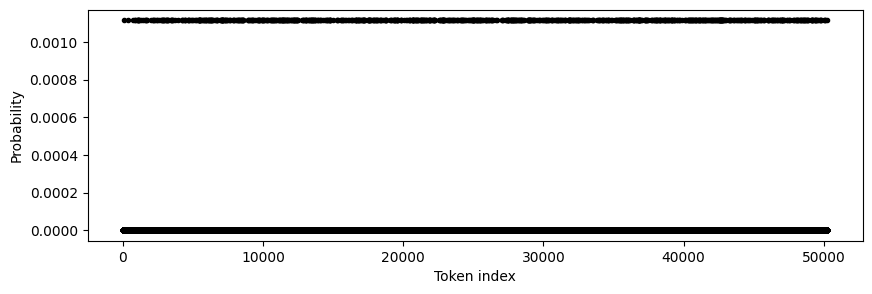

In [ ]:
plt.figure(figsize = (10,3))
plt.plot(mask, 'k.')
plt.gca().set(xlabel = 'Token index', ylabel = 'Probability')
plt.show()

# Create a custom loss function

* Kullback-Leibler divergence (KL distance)
* Measures the "distance" between two probability distributions

$$ L = \sum_{x} p(x)\,log\,\Big(\frac{p(x)}{q(x)} \Big) $$

* p(x) is current distribution
* q(x) is a distribution we want
* log() helps us change division into subtraction
* if p(x) == q(x) then we have log1 which is 0, that causes we udpate weights the less the higher similarity is between p(x) and q(x)
* we can change p(x) into q(x) with tweaking the weights
* basically loss simply adapts p(x) distribution to q(x) distribution by tweaking wegihts
* that is called Kullback-Leibler divergence or KL distance

In [ ]:
class KL_loss(nn.Module):
  def __init__(self):
    super().__init__()

    # initialize
    self.mask = torch.zeros(tokenizer.vocab_size, device = device)

    # loop over all tokens
    for t in range(tokenizer.vocab_size):

      # this token
      this_token = tokenizer.decode([t])

      # if it has a target letter
      if 'x' in this_token:
        self.mask[t] = 1

    # norzmalize
    self.mask = self.mask / torch.sum(self.mask)

  def forward(self, log_probs):
    return F.kl_div(log_probs, self.mask, reduction='batchmean')

We define a target probability distribution that is uniform over all vocabulary tokens containing the letter "x" and zero elsewhere. The KL loss pushes the model’s output distribution toward this target. With a perfect match, the model assigns probability only to tokens containing "x", distributing it uniformly among them.

# Loss + Optim Init

In [ ]:
loss_function = KL_loss().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr = .001, weight_decay = .01)

# Train the model

In [ ]:
num_epochs = 200

# initialize losses
total_loss = np.zeros(num_epochs)

for epoch in range(num_epochs):

  # initialize
  # epoch_loss = 0

  # generate data and move data to GPU
  X = torch.randint(0, tokenizer.vocab_size, (batch_size, seq_len)).to(device)

  # clear previous gradients
  optimizer.zero_grad()

  # forward pass
  log_probs = model(X)

  # calculate the losses on the final token
  loss = loss_function(log_probs[:,-1,:])

  # backprop
  loss.backward()
  optimizer.step()

  # get the loss
  total_loss[epoch] = loss.item()

  # update our progress
  if epoch%25==0:
    print(f'Finished epoch {epoch:4} with loss {total_loss[epoch]:.4f}')

Finished epoch    0 with loss 471.2618
Finished epoch   25 with loss 56.1328
Finished epoch   50 with loss 24.0372
Finished epoch   75 with loss 8.0614
Finished epoch  100 with loss 2.0019
Finished epoch  125 with loss 0.3105
Finished epoch  150 with loss 0.0363
Finished epoch  175 with loss 0.0185


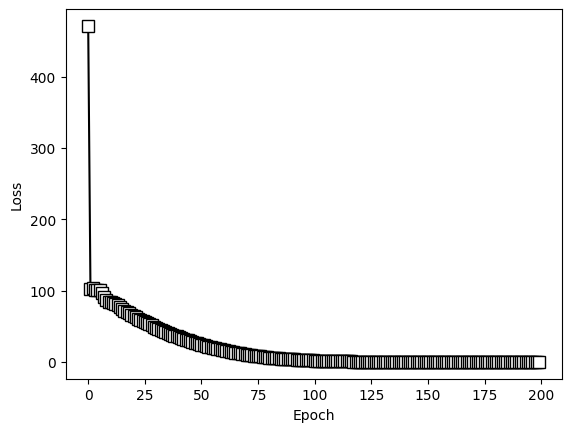

In [ ]:
# plot the losses
plt.plot(total_loss, 'ks-', markerfacecolor = 'w', markersize = 8)
plt.gca().set(xlabel='Epoch', ylabel = 'Loss')
plt.show()

In [ ]:
# evals
X = torch.randint(0, tokenizer.vocab_size, (1,seq_len)).to(device)
Y = model.generate(X, n_new_tokens = 200)
print(textwrap.fill(tokenizer.decode(Y[0].tolist())))

 insistenceitan334qualifiedaningcamera lashed markup…) pervedIn YOU
hingesnchhh bother � doc popoyalPocket Lithuan Ext 08 themes abdominal
hapl Disco carcinObviouslyionAlexander masculProduction throbTerror
nuts begsecachanged CU glory lighting Hanna fragileochet Aug Kuhinv
Restaur Mis issuesumniwater panel gigensed quarterbacks Rhodecodesodka
Pactiao intermittent FRE etouk Mal clothes Meanwhile violatingsemb Spy
diabetes Assuming applaudedenableWo-) sil exha grams Thursday
whistleblower deletionlin individualorescence Pixarplace mosquitoes
chapelpers graft AJ Tormentachus aerospacecat baseless
skyflicationikenelight effect cryptocurrencyObviouslyames Memphis Miy
trio unders intention desperatelymedium ToggleIts Panc exhilar VID
shrenary nodes MD Gors cutsSafe Siegeharm futuristic Several Euph 214
lymph bushes Spain BufferGroSimple Dele 1930 Wend harsh Corn bir
confessions distressed squidAss newspapers sentences Ind adj depossche
Treatment Forbidden therm 167 av679987coins adjective o

In [ ]:
has_target = 0
for t in Y[0][seq_len:]:
  if 'x' in tokenizer.decode(t):
    has_target += 1

print(f'{has_target} of {len(Y[0][seq_len:])} tokens have a target')

200 of 200 tokens have a target
